# PROJETO FINAL — PREVISÃO DE VITÓRIA NO LEAGUE OF LEGENDS

## Problemática de negócio

Uma equipe de análise de desempenho de jogos competitivos deseja identificar, ainda no início de uma partida, quais fatores estão associados à maior probabilidade de vitória do time azul.

A ideia é utilizar dados registrados nos primeiros minutos da partida para construir um modelo capaz de classificar se o **time azul vencerá (1)** ou **não vencerá (0)**.

### Por que dados e Machine Learning são pertinentes?

Uma partida reúne muitas informações simultâneas: ouro, experiência, eliminações, objetivos, visão e progresso de cada equipe. A análise de dados permite descobrir quais desses fatores estão mais associados ao resultado final.

O Machine Learning é pertinente porque, além de descrever os padrões, pode aprender com partidas anteriores e produzir uma **previsão para novas partidas**.

### Pergunta principal

> **É possível prever a vitória do time azul utilizando informações disponíveis no início da partida?**

### Tipo de problema

**Classificação binária.**

### Variável-alvo

`blueWins`

- `0` = o time azul perdeu
- `1` = o time azul venceu

### Observação importante sobre o escopo

A base utilizada contém informações coletadas após os primeiros 10 minutos das partidas. Portanto, a previsão representa uma **avaliação de vantagem no início da partida**, e não uma previsão feita antes do jogo começar.

# 1. Fonte dos dados

A base utilizada é **League of Legends Diamond Ranked Games (10 min)**, disponibilizada publicamente no Kaggle.

**Fonte:** Kaggle — https://www.kaggle.com/datasets/bobbyscience/league-of-legends-diamond-ranked-games-10-min

A documentação pública da base descreve aproximadamente 10 mil partidas ranqueadas de alto nível e informa que as características foram coletadas após os primeiros 10 minutos de jogo. A variável `blueWins` é o alvo, indicando se o time azul venceu. citeturn791426search0turn791426search3

A base fornecida neste projeto possui **9.879 partidas e 40 colunas**, sendo `gameId` o identificador e `blueWins` a variável-alvo.

# 2. Bibliotecas

Vamos utilizar ferramentas para:

- manipulação dos dados;
- análise estatística;
- visualização;
- divisão treino/teste;
- validação cruzada;
- otimização de hiperparâmetros;
- Árvore de Decisão;
- XGBoost;
- avaliação dos modelos.

In [32]:
import os

import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### Justificativa

Árvore de Decisão e XGBoost foram escolhidos porque são adequados para dados tabulares e conseguem capturar relações não lineares entre os indicadores de desempenho da partida.

Também usaremos `GridSearchCV` e validação cruzada para comparar configurações sem escolher os hiperparâmetros de forma arbitrária.

# 3. Carregamento dos dados

In [33]:
# Leitura com caminho relativo (reprodutível)
df = pd.read_csv('LOL_RANKED.csv')

print(f"Shape: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("\nPrimeiras 5 linhas:")
df.head()

Shape: 9879 linhas x 40 colunas

Primeiras 5 linhas:


,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,blueHeralds,blueTowersDestroyed,blueTotalGold,blueAvgLevel,blueTotalExperience,blueTotalMinionsKilled,blueTotalJungleMinionsKilled,blueGoldDiff,blueExperienceDiff,blueCSPerMin,blueGoldPerMin,redWardsPlaced,redWardsDestroyed,redFirstBlood,redKills,redDeaths,redAssists,redEliteMonsters,redDragons,redHeralds,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
0,4519157822,0,28,2,1,9,6,11,0,0,0,0,17210,6.6,17039,195,36,643,-8,19.5,1721.0,15,6,0,6,9,8,0,0,0,0,16567,6.8,17047,197,55,-643,8,19.7,1656.7
1,4523371949,0,12,1,0,5,5,5,0,0,0,0,14712,6.6,16265,174,43,-2908,-1173,17.4,1471.2,12,1,1,5,5,2,2,1,1,1,17620,6.8,17438,240,52,2908,1173,24.0,1762.0
2,4521474530,0,15,0,0,7,11,4,1,1,0,0,16113,6.4,16221,186,46,-1172,-1033,18.6,1611.3,15,3,1,11,7,14,0,0,0,0,17285,6.8,17254,203,28,1172,1033,20.3,1728.5
3,4524384067,0,43,1,0,4,5,5,1,0,1,0,15157,7.0,17954,201,55,-1321,-7,20.1,1515.7,15,2,1,5,4,10,0,0,0,0,16478,7.0,17961,235,47,1321,7,23.5,1647.8
4,4436033771,0,75,4,0,6,6,6,0,0,0,0,16400,7.0,18543,210,57,-1004,230,21.0,1640.0,17,2,1,6,6,7,1,1,0,0,17404,7.0,18313,225,67,1004,-230,22.5,1740.4


### Insight

A base possui 9.879 partidas e 40 colunas.

Cada linha representa uma partida. As variáveis descrevem o desempenho dos times em um momento inicial da partida.

O `gameId` é apenas um identificador e será retirado antes do treinamento.

# 4. EDA — tipos, nulos e duplicidades

In [34]:
print("Tipos das variáveis:")
display(df.dtypes)

print("\nValores ausentes:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nLinhas duplicadas:")
print(df.duplicated().sum())

Tipos das variáveis:


gameId                            int64
blueWins                          int64
blueWardsPlaced                   int64
blueWardsDestroyed                int64
blueFirstBlood                    int64
blueKills                         int64
blueDeaths                        int64
blueAssists                       int64
blueEliteMonsters                 int64
blueDragons                       int64
blueHeralds                       int64
blueTowersDestroyed               int64
blueTotalGold                     int64
blueAvgLevel                    float64
blueTotalExperience               int64
blueTotalMinionsKilled            int64
blueTotalJungleMinionsKilled      int64
blueGoldDiff                      int64
blueExperienceDiff                int64
blueCSPerMin                    float64
blueGoldPerMin                  float64
redWardsPlaced                    int64
redWardsDestroyed                 int64
redFirstBlood                     int64
redKills                          int64



Valores ausentes:


gameId                          0
blueWins                        0
blueWardsPlaced                 0
blueWardsDestroyed              0
blueFirstBlood                  0
blueKills                       0
blueDeaths                      0
blueAssists                     0
blueEliteMonsters               0
blueDragons                     0
blueHeralds                     0
blueTowersDestroyed             0
blueTotalGold                   0
blueAvgLevel                    0
blueTotalExperience             0
blueTotalMinionsKilled          0
blueTotalJungleMinionsKilled    0
blueGoldDiff                    0
blueExperienceDiff              0
blueCSPerMin                    0
blueGoldPerMin                  0
redWardsPlaced                  0
redWardsDestroyed               0
redFirstBlood                   0
redKills                        0
redDeaths                       0
redAssists                      0
redEliteMonsters                0
redDragons                      0
redHeralds    


Linhas duplicadas:
0


### Insight

A base não apresenta valores ausentes e as variáveis estão em formatos numéricos adequados à modelagem.

Isso simplifica a etapa de preparação: não será necessária imputação.

Também verificamos duplicidades para garantir que a mesma partida não apareça repetida de forma idêntica.

# 5. EDA — estatísticas descritivas

In [35]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
gameId,9879.0,4.500084e+09,2.757328e+07,4.295358e+09,4.483301e+09,4.510920e+09,4.521733e+09,4.527991e+09
blueWins,9879.0,4.990384e-01,5.000244e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
blueWardsPlaced,9879.0,2.228829e+01,1.801918e+01,5.000000e+00,1.400000e+01,1.600000e+01,2.000000e+01,2.500000e+02
blueWardsDestroyed,9879.0,2.824881e+00,2.174998e+00,0.000000e+00,1.000000e+00,3.000000e+00,4.000000e+00,2.700000e+01
blueFirstBlood,9879.0,5.048082e-01,5.000022e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
blueKills,9879.0,6.183925e+00,3.011028e+00,0.000000e+00,4.000000e+00,6.000000e+00,8.000000e+00,2.200000e+01
blueDeaths,9879.0,6.137666e+00,2.933818e+00,0.000000e+00,4.000000e+00,6.000000e+00,8.000000e+00,2.200000e+01
blueAssists,9879.0,6.645106e+00,4.064520e+00,0.000000e+00,4.000000e+00,6.000000e+00,9.000000e+00,2.900000e+01
blueEliteMonsters,9879.0,5.499544e-01,6.255265e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.000000e+00
blueDragons,9879.0,3.619800e-01,4.805974e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00


### Insight

As estatísticas descritivas permitem observar escala, média, dispersão, mínimo e máximo de cada indicador.

Essa etapa é importante porque as variáveis estão em escalas diferentes: algumas representam contagens, outras representam ouro, experiência ou taxas por minuto.

Também ajuda a identificar valores extremos que precisam ser interpretados antes da modelagem.

# 6. EDA — distribuição da variável-alvo

Quantidade por classe:


blueWins
0    4949
1    4930
Name: count, dtype: int64

Percentual por classe:


blueWins
0    50.1
1    49.9
Name: proportion, dtype: float64

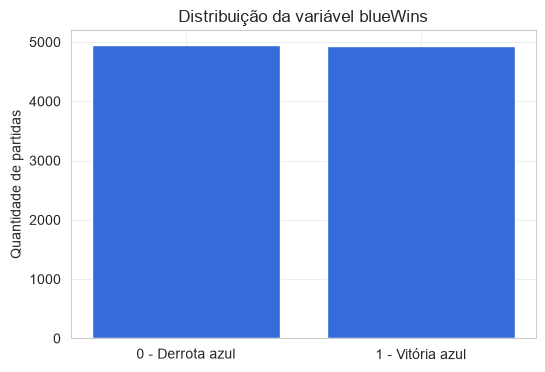

In [36]:
contagem = df["blueWins"].value_counts().sort_index()
percentual = df["blueWins"].value_counts(normalize=True).sort_index() * 100

print("Quantidade por classe:")
display(contagem)

print("Percentual por classe:")
display(percentual.round(2))

plt.figure(figsize=(6, 4))
plt.bar(["0 - Derrota azul", "1 - Vitória azul"], contagem.values)
plt.title("Distribuição da variável blueWins")
plt.ylabel("Quantidade de partidas")
plt.xticks(rotation=0)
plt.show()

### Insight

A variável-alvo está praticamente equilibrada: aproximadamente metade das partidas termina com vitória azul e metade com derrota azul.

Isso é positivo para a classificação, pois não existe um desbalanceamento forte que obrigue o uso de técnicas como SMOTE ou `class_weight`.

# 7. EDA — comparação de indicadores entre vencedores e perdedores

In [37]:
variaveis_comparacao = [
    "blueGoldDiff",
    "blueExperienceDiff",
    "blueKills",
    "blueAssists",
    "blueTowersDestroyed"
]

resumo_grupos = df.groupby("blueWins")[variaveis_comparacao].mean().T

print("Médias por resultado:")
display(resumo_grupos.round(2))

Médias por resultado:


blueWins,0,1
blueGoldDiff,-1237.07,1270.72
blueExperienceDiff,-971.90,908.27
blueKills,5.17,7.20
blueAssists,5.52,7.77
blueTowersDestroyed,0.02,0.08


### Insight

A comparação das médias permite identificar quais indicadores apresentam diferenças mais claras entre partidas vencidas e perdidas pelo time azul.

Em especial, `blueGoldDiff` e `blueExperienceDiff` são variáveis de vantagem acumulada: valores positivos significam vantagem do time azul em relação ao adversário.

Esse tipo de variável tende a ser muito informativo para uma análise de estado da partida.

# 8. EDA — distribuição do Gold Difference

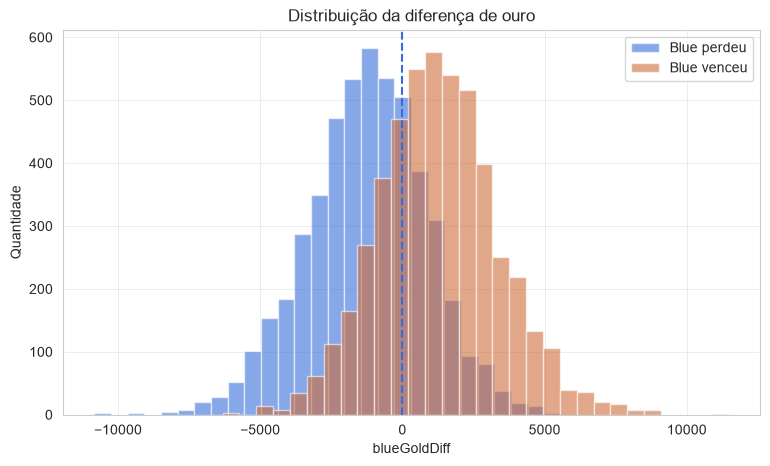

In [38]:
plt.figure(figsize=(9, 5))

plt.hist(
    df.loc[df["blueWins"] == 0, "blueGoldDiff"],
    bins=30,
    alpha=0.6,
    label="Blue perdeu"
)

plt.hist(
    df.loc[df["blueWins"] == 1, "blueGoldDiff"],
    bins=30,
    alpha=0.6,
    label="Blue venceu"
)

plt.axvline(0, linestyle="--")
plt.title("Distribuição da diferença de ouro")
plt.xlabel("blueGoldDiff")
plt.ylabel("Quantidade")
plt.legend()
plt.show()

### Insight

A diferença de ouro é um dos indicadores mais importantes da situação econômica de uma equipe durante a partida.

Quando o `blueGoldDiff` é positivo, o time azul possui mais ouro acumulado que o time vermelho. A separação visual entre as distribuições ajuda a entender por que essa variável pode ser útil para prever o resultado final.

# 9. EDA — boxplots e identificação de valores extremos

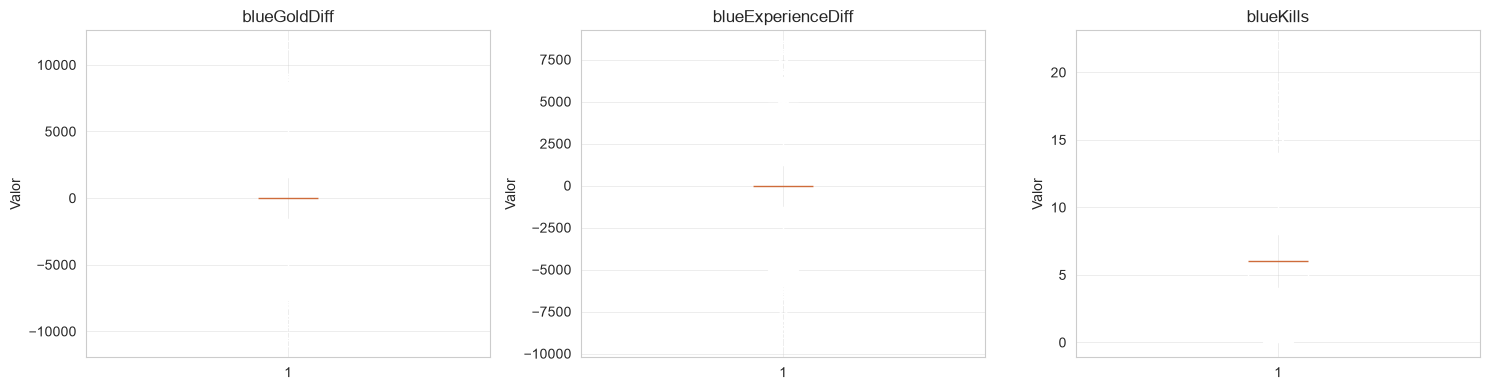

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, coluna in zip(
    axes,
    ["blueGoldDiff", "blueExperienceDiff", "blueKills"]
):
    ax.boxplot(df[coluna])
    ax.set_title(coluna)
    ax.set_ylabel("Valor")

plt.tight_layout()
plt.show()

### Insight

Os boxplots ajudam a identificar valores muito afastados do centro da distribuição.

Um valor extremo não deve ser removido automaticamente: em dados de partidas, uma grande diferença de ouro ou experiência pode representar uma partida real com vantagem excepcional.

Por isso, valores extremos serão preservados nesta etapa, desde que não representem erro de registro.

# 10. EDA — matriz de correlação

Variáveis com maior correlação absoluta com blueWins:


redGoldDiff           -0.5111
blueGoldDiff           0.5111
blueExperienceDiff     0.4896
redExperienceDiff     -0.4896
blueTotalGold          0.4172
blueGoldPerMin         0.4172
redTotalGold          -0.4114
redGoldPerMin         -0.4114
blueTotalExperience    0.3961
redTotalExperience    -0.3876
Name: blueWins, dtype: float64

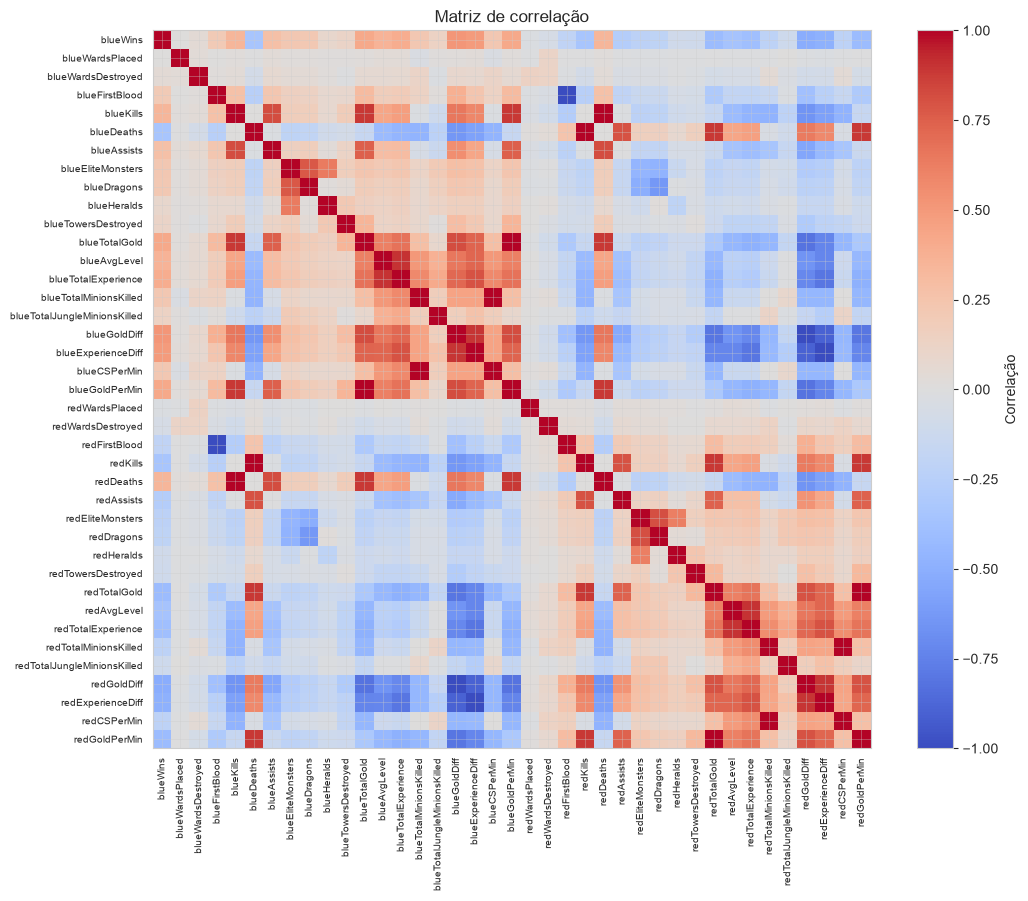

In [40]:
corr = df.drop(columns=["gameId"]).corr(numeric_only=True)["blueWins"]
corr_ordenada = corr.drop("blueWins").sort_values(key=abs, ascending=False)

print("Variáveis com maior correlação absoluta com blueWins:")
display(corr_ordenada.head(10).round(4))

matriz = df.drop(columns=["gameId"]).corr(numeric_only=True)

plt.figure(figsize=(11, 9))
plt.imshow(matriz, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlação")
plt.xticks(range(len(matriz.columns)), matriz.columns, rotation=90, fontsize=7)
plt.yticks(range(len(matriz.index)), matriz.index, fontsize=7)
plt.title("Matriz de correlação")
plt.tight_layout()
plt.show()

Variáveis com maior correlação absoluta com blueWins:


redGoldDiff           -0.5111
blueGoldDiff           0.5111
blueExperienceDiff     0.4896
redExperienceDiff     -0.4896
blueTotalGold          0.4172
blueGoldPerMin         0.4172
redTotalGold          -0.4114
redGoldPerMin         -0.4114
blueTotalExperience    0.3961
redTotalExperience    -0.3876
Name: blueWins, dtype: float64

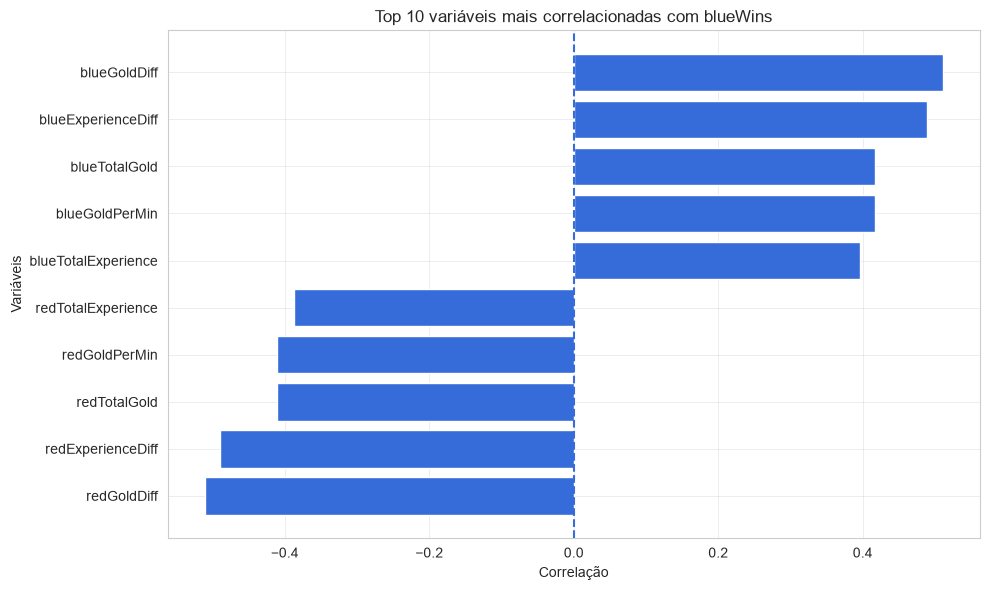

In [41]:
# Correlação das variáveis com blueWins
Mcorr = df.drop(columns=["gameId"]).corr(numeric_only=True)["blueWins"]

# Remove a própria blueWins e ordena pela correlação absoluta
corr_ordenada = Mcorr.drop("blueWins").sort_values(key=abs, ascending=False)

# Mostrar as 10 maiores correlações
print("Variáveis com maior correlação absoluta com blueWins:")
display(corr_ordenada.head(10).round(4))

# Gráfico das 10 maiores correlações
top10 = corr_ordenada.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top10.index,
    top10.values
)

plt.axvline(0, linestyle="--")

plt.title("Top 10 variáveis mais correlacionadas com blueWins")
plt.xlabel("Correlação")
plt.ylabel("Variáveis")

plt.tight_layout()
plt.show()

### Insight — correlação


A correlação permite observar a relação linear entre cada variável e `blueWins`.

Na base, `blueGoldDiff` e `redGoldDiff` apresentam correlações fortes e opostas com o alvo, assim como `blueExperienceDiff` e `redExperienceDiff`.

Isso também revela uma **armadilha estrutural da base**: algumas variáveis são espelhos matemáticos umas das outras. Por exemplo, uma vantagem de ouro do azul é exatamente uma desvantagem de ouro do vermelho.

Para reduzir redundância, manteremos as variáveis comparativas do lado azul e retiraremos alguns espelhos do lado vermelho.

# 11. Preparação — remoção de identificador e variáveis redundantes

In [42]:
colunas_redundantes = [
    "gameId",
    "redGoldDiff",
    "redExperienceDiff",
    "redKills",
    "redDeaths"
]

df_modelo = df.drop(columns=colunas_redundantes).copy()

print("Colunas removidas:", colunas_redundantes)
print("Dimensão após a limpeza:", df_modelo.shape)
display(df_modelo.head())

Colunas removidas: ['gameId', 'redGoldDiff', 'redExperienceDiff', 'redKills', 'redDeaths']
Dimensão após a limpeza: (9879, 35)


,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,blueHeralds,blueTowersDestroyed,blueTotalGold,blueAvgLevel,blueTotalExperience,blueTotalMinionsKilled,blueTotalJungleMinionsKilled,blueGoldDiff,blueExperienceDiff,blueCSPerMin,blueGoldPerMin,redWardsPlaced,redWardsDestroyed,redFirstBlood,redAssists,redEliteMonsters,redDragons,redHeralds,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redCSPerMin,redGoldPerMin
0,0,28,2,1,9,6,11,0,0,0,0,17210,6.6,17039,195,36,643,-8,19.5,1721.0,15,6,0,8,0,0,0,0,16567,6.8,17047,197,55,19.7,1656.7
1,0,12,1,0,5,5,5,0,0,0,0,14712,6.6,16265,174,43,-2908,-1173,17.4,1471.2,12,1,1,2,2,1,1,1,17620,6.8,17438,240,52,24.0,1762.0
2,0,15,0,0,7,11,4,1,1,0,0,16113,6.4,16221,186,46,-1172,-1033,18.6,1611.3,15,3,1,14,0,0,0,0,17285,6.8,17254,203,28,20.3,1728.5
3,0,43,1,0,4,5,5,1,0,1,0,15157,7.0,17954,201,55,-1321,-7,20.1,1515.7,15,2,1,10,0,0,0,0,16478,7.0,17961,235,47,23.5,1647.8
4,0,75,4,0,6,6,6,0,0,0,0,16400,7.0,18543,210,57,-1004,230,21.0,1640.0,17,2,1,7,1,1,0,0,17404,7.0,18313,225,67,22.5,1740.4


### Justificativa

`gameId` não representa uma característica do desempenho e, portanto, não deve orientar a previsão.

As demais colunas removidas representam informações espelhadas ou diretamente equivalentes entre os dois times. Removê-las reduz redundância sem retirar a informação comparativa principal.

Essa decisão atende a um ponto importante de qualidade metodológica: reconhecer uma particularidade estrutural da base em vez de simplesmente treinar o modelo com todas as colunas.

# 12. Separação em X e y

In [43]:
X = df_modelo.drop(columns=["blueWins"])
y = df_modelo["blueWins"]

print("X:", X.shape)
print("y:", y.shape)

display(X.head())
display(y.head())

X: (9879, 34)
y: (9879,)


,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,blueHeralds,blueTowersDestroyed,blueTotalGold,blueAvgLevel,blueTotalExperience,blueTotalMinionsKilled,blueTotalJungleMinionsKilled,blueGoldDiff,blueExperienceDiff,blueCSPerMin,blueGoldPerMin,redWardsPlaced,redWardsDestroyed,redFirstBlood,redAssists,redEliteMonsters,redDragons,redHeralds,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redCSPerMin,redGoldPerMin
0,28,2,1,9,6,11,0,0,0,0,17210,6.6,17039,195,36,643,-8,19.5,1721.0,15,6,0,8,0,0,0,0,16567,6.8,17047,197,55,19.7,1656.7
1,12,1,0,5,5,5,0,0,0,0,14712,6.6,16265,174,43,-2908,-1173,17.4,1471.2,12,1,1,2,2,1,1,1,17620,6.8,17438,240,52,24.0,1762.0
2,15,0,0,7,11,4,1,1,0,0,16113,6.4,16221,186,46,-1172,-1033,18.6,1611.3,15,3,1,14,0,0,0,0,17285,6.8,17254,203,28,20.3,1728.5
3,43,1,0,4,5,5,1,0,1,0,15157,7.0,17954,201,55,-1321,-7,20.1,1515.7,15,2,1,10,0,0,0,0,16478,7.0,17961,235,47,23.5,1647.8
4,75,4,0,6,6,6,0,0,0,0,16400,7.0,18543,210,57,-1004,230,21.0,1640.0,17,2,1,7,1,1,0,0,17404,7.0,18313,225,67,22.5,1740.4


0    0
1    0
2    0
3    0
4    0
Name: blueWins, dtype: int64

### Insight

`X` contém as informações disponíveis para explicar o resultado da partida.

`y` contém apenas o resultado que queremos prever.

Separar essas duas estruturas evita que o algoritmo receba diretamente a resposta durante o treinamento.

# 13. Divisão treino e teste

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (7903, 34)
X_test : (1976, 34)
y_train: (7903,)
y_test : (1976,)


### Justificativa

Os dados são separados **antes de qualquer transformação que aprenderia parâmetros da base**.

Usamos 80% para treino e 20% para teste.

`stratify=y` preserva a proporção das classes.

Isso evita vazamento de dados e permite que o conjunto de teste represente uma avaliação final do desempenho.

# 14. Padronização — decisão técnica

A padronização com `StandardScaler` **não será aplicada ao treinamento principal** porque os modelos escolhidos são baseados em árvores de decisão.

Árvores e XGBoost fazem divisões por limiares nas variáveis e não dependem da distância entre escalas da mesma forma que modelos como SVM ou KNN.

Assim, não aplicar a padronização aqui é uma decisão técnica justificada, e não uma etapa esquecida.

Também evitamos criar uma transformação desnecessária que poderia deixar o fluxo mais complexo sem benefício para esses modelos.

# 15. Modelo 1 — Árvore de Decisão + validação cruzada

In [45]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

parametros_arvore = {
    "max_depth": [2, 3, 4, 5, 7, 10],
    "min_samples_leaf": [1, 2, 5, 10]
}

grid_arvore = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    parametros_arvore,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_arvore.fit(X_train, y_train)

print("Melhores parâmetros:")
print(grid_arvore.best_params_)

print("Melhor média na validação cruzada:")
print(round(grid_arvore.best_score_, 4))

Melhores parâmetros:
{'max_depth': 2, 'min_samples_leaf': 1}
Melhor média na validação cruzada:
0.7224


### Justificativa

A Árvore de Decisão foi usada como primeiro modelo porque é simples de interpretar e funciona muito bem como modelo de referência em problemas tabulares.

Foram ajustados `max_depth` e `min_samples_leaf` para controlar a complexidade da árvore e reduzir o risco de sobreajuste.

A validação cruzada utiliza cinco divisões estratificadas dos dados de treinamento.

# 16. Modelo 2 — XGBoost + validação cruzada

In [46]:
parametros_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [2, 3, 5],
    "learning_rate": [0.05, 0.10]
}

modelo_xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

grid_xgb = GridSearchCV(
    modelo_xgb,
    parametros_xgb,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)

print("Melhores parâmetros:")
print(grid_xgb.best_params_)

print("Melhor média na validação cruzada:")
print(round(grid_xgb.best_score_, 4))

Melhores parâmetros:
{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
Melhor média na validação cruzada:
0.7347


### Justificativa

O XGBoost foi escolhido como segundo modelo por ser um método de boosting baseado em árvores, capaz de combinar várias árvores para melhorar a previsão.

Foram ajustados três hiperparâmetros:

- `n_estimators`: número de árvores;
- `max_depth`: profundidade máxima;
- `learning_rate`: velocidade de aprendizagem.

Assim, temos um segundo modelo com uma estratégia diferente de construção das árvores, permitindo uma comparação real.

# 17. Avaliação dos dois modelos

In [47]:
modelos = {
    "Árvore de Decisão": grid_arvore.best_estimator_,
    "XGBoost": grid_xgb.best_estimator_
}

resultados = []

for nome, modelo in modelos.items():
    previsoes = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)[:, 1]

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, previsoes),
        "Precisão": precision_score(y_test, previsoes),
        "Recall": recall_score(y_test, previsoes),
        "F1-score": f1_score(y_test, previsoes),
        "ROC AUC": roc_auc_score(y_test, probabilidades)
    })

resultados_df = pd.DataFrame(resultados)

display(resultados_df.round(4))

,Modelo,Acurácia,Precisão,Recall,F1-score,ROC AUC
0,Árvore de Decisão,0.7206,0.7343,0.6897,0.7113,0.7809
1,XGBoost,0.7262,0.7254,0.7262,0.7258,0.8064


### Insight

As métricas permitem avaliar o desempenho sob diferentes perspectivas.

A acurácia mostra o percentual total de acertos. Precisão mede a qualidade das previsões positivas, recall mostra quanto da classe positiva foi identificado e F1-score equilibra precisão e recall.

O ROC AUC avalia a capacidade de separação utilizando as probabilidades do modelo.

A decisão final não deve ser baseada em uma única métrica.

# 18. Matrizes de confusão

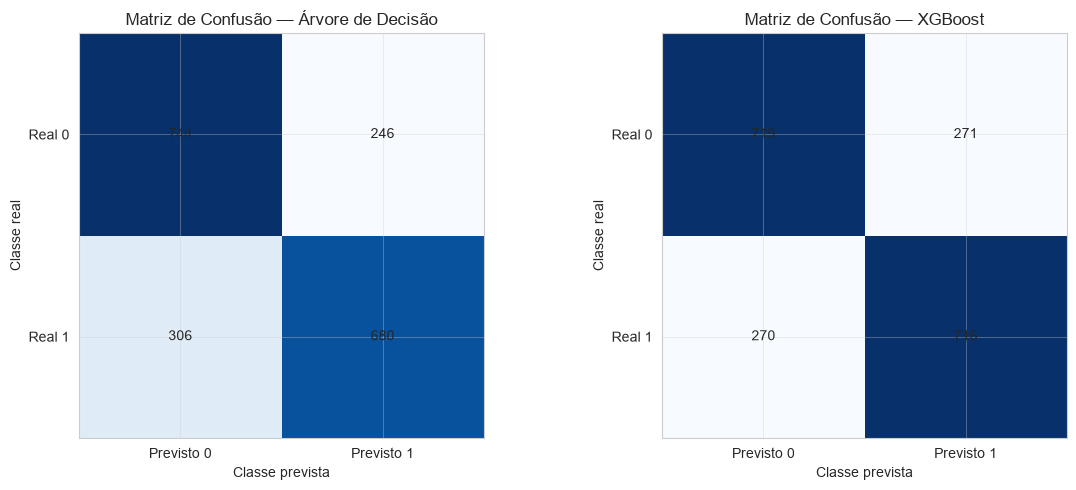

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nome, modelo) in zip(axes, modelos.items()):
    previsoes = modelo.predict(X_test)
    cm = confusion_matrix(y_test, previsoes)

    ax.imshow(cm, cmap="Blues")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Previsto 0", "Previsto 1"])

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Real 0", "Real 1"])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")

    ax.set_title(f"Matriz de Confusão — {nome}")
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")

plt.tight_layout()
plt.show()

### Insight — matriz de confusão

A matriz de confusão mostra os quatro resultados possíveis:

- **Verdadeiro negativo:** previu derrota azul e realmente ocorreu derrota.
- **Falso positivo:** previu vitória azul, mas o azul perdeu.
- **Falso negativo:** previu derrota azul, mas o azul venceu.
- **Verdadeiro positivo:** previu vitória azul e acertou.

Para uma equipe de análise competitiva, falsos positivos e falsos negativos representam tipos diferentes de erro na avaliação da situação da partida.

# 19. Curvas ROC

<Figure size 800x600 with 0 Axes>

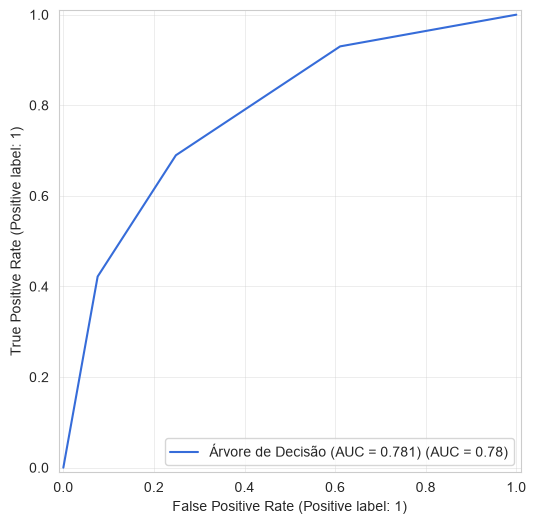

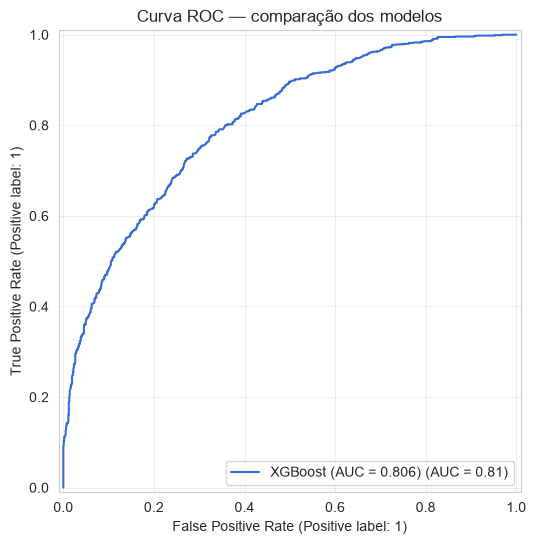

In [49]:
plt.figure(figsize=(8, 6))

for nome, modelo in modelos.items():
    probabilidades = modelo.predict_proba(X_test)[:, 1]
    roc_display = RocCurveDisplay.from_predictions(
        y_test,
        probabilidades,
        name=f"{nome} (AUC = {roc_auc_score(y_test, probabilidades):.3f})"
    )

plt.title("Curva ROC — comparação dos modelos")
plt.show()


### Insight

A curva ROC mostra a capacidade dos modelos de separar partidas que terminarão em vitória ou derrota do time azul.

O modelo com maior AUC apresenta melhor capacidade de discriminação, considerando diferentes pontos de corte.

# 20. Importância das variáveis

Top variáveis — Árvore de Decisão:


,Variavel,Arvore,XGBoost
15,blueGoldDiff,1.0,0.3675
0,blueWardsPlaced,0.0,0.0131
1,blueWardsDestroyed,0.0,0.0000
2,blueFirstBlood,0.0,0.0000
4,blueDeaths,0.0,0.0078
3,blueKills,0.0,0.0341
6,blueEliteMonsters,0.0,0.0024
7,blueDragons,0.0,0.0694
8,blueHeralds,0.0,0.0000
5,blueAssists,0.0,0.0000


Top variáveis — XGBoost:


,Variavel,Arvore,XGBoost
15,blueGoldDiff,1.0,0.3675
16,blueExperienceDiff,0.0,0.2412
7,blueDragons,0.0,0.0694
24,redDragons,0.0,0.0622
11,blueAvgLevel,0.0,0.0363
3,blueKills,0.0,0.0341
29,redTotalExperience,0.0,0.0326
27,redTotalGold,0.0,0.0289
10,blueTotalGold,0.0,0.0273
12,blueTotalExperience,0.0,0.0255


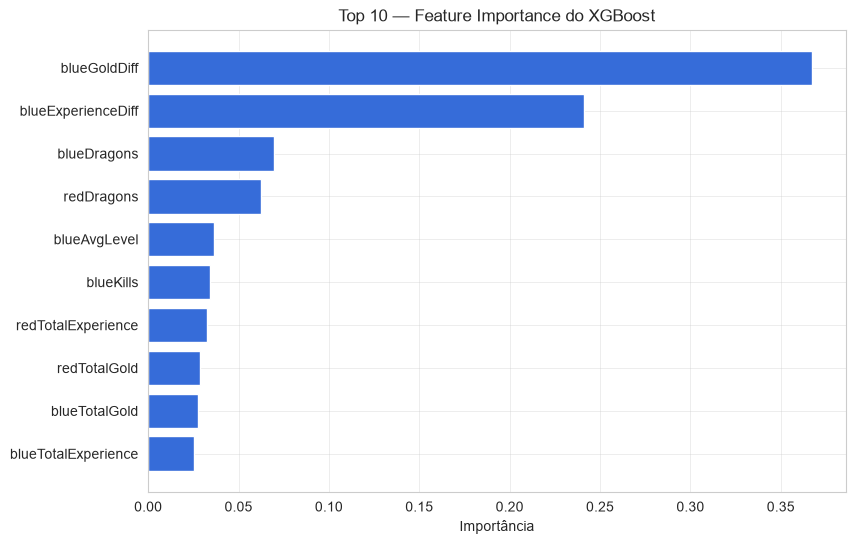

In [50]:
arvore_final = grid_arvore.best_estimator_
xgb_final = grid_xgb.best_estimator_

importancias = pd.DataFrame({
    "Variavel": X.columns,
    "Arvore": arvore_final.feature_importances_,
    "XGBoost": xgb_final.feature_importances_
})

print("Top variáveis — Árvore de Decisão:")
display(
    importancias.sort_values("Arvore", ascending=False)
    .head(10)
    .round(4)
)

print("Top variáveis — XGBoost:")
display(
    importancias.sort_values("XGBoost", ascending=False)
    .head(10)
    .round(4)
)

top_xgb = importancias.sort_values("XGBoost", ascending=False).head(10)

plt.figure(figsize=(9, 6))
plt.barh(top_xgb["Variavel"][::-1], top_xgb["XGBoost"][::-1])
plt.title("Top 10 — Feature Importance do XGBoost")
plt.xlabel("Importância")
plt.show()

### Insight

A importância das variáveis mostra quais indicadores o modelo utilizou com maior frequência para realizar suas decisões.

É esperado que indicadores de vantagem, especialmente **diferença de ouro e diferença de experiência**, apareçam entre os mais relevantes.

Isso faz sentido do ponto de vista do negócio: uma equipe que já acumulou vantagem econômica e de experiência nos primeiros minutos tende a estar em uma situação diferente do adversário.

# 21. Correlação × importância do modelo

In [51]:
comparacao = pd.DataFrame({
    "Correlacao_com_blueWins": df_modelo.corr(numeric_only=True)["blueWins"].drop("blueWins"),
    "Importancia_Arvore": pd.Series(arvore_final.feature_importances_, index=X.columns),
    "Importancia_XGBoost": pd.Series(xgb_final.feature_importances_, index=X.columns)
})

display(
    comparacao.sort_values(
        "Correlacao_com_blueWins",
        key=abs,
        ascending=False
    ).head(10).round(4)
)

,Correlacao_com_blueWins,Importancia_Arvore,Importancia_XGBoost
blueGoldDiff,0.5111,1.0,0.3675
blueExperienceDiff,0.4896,0.0,0.2412
blueTotalGold,0.4172,0.0,0.0273
blueGoldPerMin,0.4172,0.0,0.0000
redTotalGold,-0.4114,0.0,0.0289
redGoldPerMin,-0.4114,0.0,0.0000
blueTotalExperience,0.3961,0.0,0.0255
redTotalExperience,-0.3876,0.0,0.0326
blueAvgLevel,0.3578,0.0,0.0363
redAvgLevel,-0.3521,0.0,0.0000


### Insight — interpretação crítica

Correlação e importância do modelo não significam a mesma coisa.

A correlação mede uma relação linear entre uma variável e o alvo. Já a importância do XGBoost considera como a variável contribui para as decisões de um conjunto de árvores.

Por isso, é possível existir uma variável com correlação moderada, mas que tenha importância diferente no modelo por participar de interações ou relações não lineares.

Neste projeto, a convergência entre `blueGoldDiff`, `blueExperienceDiff` e os resultados da modelagem reforça a interpretação de que vantagem econômica e de experiência são sinais importantes do estado da partida.

# 22. Data Storytelling — traduzindo o modelo para o negócio

In [52]:
melhor_modelo_nome = resultados_df.loc[
    resultados_df["ROC AUC"].idxmax(),
    "Modelo"
]

melhor_auc = resultados_df["ROC AUC"].max()
melhor_acuracia = resultados_df.loc[
    resultados_df["ROC AUC"].idxmax(),
    "Acurácia"
]

print(f"Modelo com maior ROC AUC: {melhor_modelo_nome}")
print(f"ROC AUC: {melhor_auc:.4f}")
print(f"Acurácia: {melhor_acuracia:.4f}")

Modelo com maior ROC AUC: XGBoost
ROC AUC: 0.8064
Acurácia: 0.7262


### Recomendação de negócio

O modelo pode ser utilizado como uma ferramenta de apoio para uma equipe de análise competitiva.

A ideia não é afirmar que uma partida está definitivamente ganha aos 10 minutos, mas transformar o estado da partida em uma **estimativa de probabilidade de vitória**.

A organização poderia utilizar essa informação para:

- identificar quais fatores mais contribuem para a vantagem;
- desenvolver estratégias de treinamento;
- analisar padrões de partidas vencidas e perdidas;
- criar indicadores de acompanhamento de desempenho.

A previsão deve ser interpretada como uma estimativa estatística, e não como garantia do resultado.

# 23. Conclusão final

O projeto percorreu o fluxo completo de Ciência de Dados:

**Problemática → fonte dos dados → EDA → limpeza → preparação → treino/teste → modelagem → validação cruzada → otimização → avaliação → interpretação → recomendação de negócio.**

A análise exploratória mostrou que indicadores de vantagem acumulada, principalmente ouro e experiência, possuem forte relação com o resultado da partida.

Foram comparados uma Árvore de Decisão e um XGBoost. Ambos foram avaliados com validação cruzada e métricas de classificação.

O principal resultado do projeto é demonstrar que dados dos primeiros minutos podem ser transformados em informações úteis para avaliar a probabilidade de vitória e compreender quais fatores estão associados à vantagem competitiva.
